# Entrenamiento de modelos

Torneo de modelos para predecir `SalePrice`:

- **Modelos:** regresiones regularizadas (Ridge, Lasso, ElasticNet), ensambles (Random Forest, Gradient Boosting) y una red neuronal artificial (MLPRegressor).
- **Optimización de hiperparámetros:** `GridSearchCV` con validación cruzada de 10 folds; la mejor configuración de cada modelo se elige por el RMSE en escala logarítmica.
- **Comparación:** contra el set de validación, con el RMSE real (en dólares, regresando el target con `np.expm1`) y el RMSE normalizado al rango de `SalePrice` en validación.
- **Sin fuga de datos:** el pipeline de feature engineering se encadena con cada modelo, por lo que se reajusta dentro de cada fold; el set de validación no se usa en ningún ajuste.

## Librerías

In [ ]:
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

## Configuración

Rutas y parámetros del entrenamiento. La división train / validación, el target y las features se leen de `pipeline_config.yaml`, para usar exactamente lo mismo que el notebook de preprocesamiento.

In [2]:
# Rutas: modificar estas variables si cambia la ubicación de las fuentes o de las salidas
PROJ_DIR = Path(os.getenv("PROJ_DIR", ".."))
CONFIG_FILE = Path(os.getenv("PIPELINE_CONFIG", PROJ_DIR / "pipeline_config.yaml"))
RAW_DATA_DIR = Path(os.getenv("RAW_DATA_DIR", PROJ_DIR / "data" / "raw"))
MODELS_DIR = Path(os.getenv("MODELS_DIR", PROJ_DIR / "models"))

TRAIN_FILE = "train.csv"
MODELO_FILE = "modelo_ganador.joblib"

with open(CONFIG_FILE, encoding="utf-8") as archivo:
    config = yaml.safe_load(archivo)

MODEL_FEATURES = config["MODEL_FEATURES"]
TARGET = config["TARGET"]
ID_COL = config["ID_COLUMN"]
TEST_SIZE = config["SPLIT"]["test_size"]
RANDOM_STATE = config["SPLIT"]["random_state"]

# Parámetros de la validación cruzada
K_FOLDS = 10
SCORING = "neg_root_mean_squared_error"  # RMSE en escala log, que es la escala del target

## Carga de datos y división train / validación

Se parte de los datos crudos y se rehace la misma división 80/20 del notebook de preprocesamiento. Se verifica que las casas de cada conjunto coincidan con las de `data/processed/`. El target se transforma con `log(1 + SalePrice)`.

In [3]:
train = pd.read_csv(RAW_DATA_DIR / TRAIN_FILE, index_col=ID_COL)

X = train[MODEL_FEATURES]
y = np.log1p(train[TARGET])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# Verificación: la división coincide con los datasets procesados
ids_train = pd.read_csv(PROJ_DIR / config["OUTPUTS"]["train"], index_col=ID_COL).index
ids_val = pd.read_csv(PROJ_DIR / config["OUTPUTS"]["validation"], index_col=ID_COL).index

print(f"X_train: {X_train.shape}  |  X_val: {X_val.shape}")
print(f"Misma división que data/processed: "
      f"{X_train.index.equals(ids_train) and X_val.index.equals(ids_val)}")

X_train: (1168, 30)  |  X_val: (292, 30)
Misma división que data/processed: True


## Pipeline de feature engineering

Se carga el pipeline de preprocesamiento guardado y se clona con `sklearn.base.clone`, que copia su configuración **sin los parámetros aprendidos**. Al encadenarlo con cada modelo, las medianas, modas, codificaciones, límites de outliers, λ de Yeo-Johnson y el escalado se vuelven a aprender en cada fold, solo con los datos de entrenamiento de ese fold.

In [4]:
pipeline_fe = clone(joblib.load(PROJ_DIR / config["OUTPUTS"]["pipeline"]))

[nombre for nombre, _ in pipeline_fe.steps]

['imputacion_categoricas',
 'imputacion_numericas',
 'agrupacion_raras',
 'codificacion',
 'outliers',
 'transformacion',
 'escalado']

## Modelos y rejillas de hiperparámetros

Cada modelo tiene entre 4 y 9 configuraciones. Además de la búsqueda, cada uno incluye mecanismos contra el sobreajuste:

| Modelo | Tipo | Control del sobreajuste |
|---|---|---|
| Ridge | Regresión | Regularización L2 (`alpha`) |
| Lasso | Regresión | Regularización L1 (`alpha`) |
| ElasticNet | Regresión | Regularización L1 + L2 (`alpha`, `l1_ratio`) |
| Random Forest | Ensamble (bagging) | Profundidad máxima, mínimo de casas por hoja y fracción de variables por división |
| Gradient Boosting | Ensamble (boosting) | Tasa de aprendizaje, árboles poco profundos y submuestreo (`subsample = 0.8`) |
| MLPRegressor | Red neuronal | Regularización L2 (`alpha`) y *early stopping* con el 10% del fold de entrenamiento |

In [5]:
modelos = {
    "Ridge": (
        Ridge(),
        {"modelo__alpha": [0.1, 1, 10, 30]},
    ),
    "Lasso": (
        Lasso(max_iter=50_000),
        {"modelo__alpha": [0.0005, 0.001, 0.005, 0.01]},
    ),
    "ElasticNet": (
        ElasticNet(max_iter=50_000),
        {"modelo__alpha": [0.0005, 0.005, 0.05], "modelo__l1_ratio": [0.2, 0.5, 0.8]},
    ),
    "RandomForest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {
            "modelo__max_depth": [None, 15],
            "modelo__min_samples_leaf": [1, 3],
            "modelo__max_features": [0.33, 1.0],
        },
    ),
    "GradientBoosting": (
        GradientBoostingRegressor(n_estimators=500, subsample=0.8, random_state=RANDOM_STATE),
        {"modelo__learning_rate": [0.03, 0.1], "modelo__max_depth": [2, 3]},
    ),
    "MLPRegressor": (
        MLPRegressor(max_iter=2_000, early_stopping=True, random_state=RANDOM_STATE),
        {
            "modelo__hidden_layer_sizes": [(64,), (64, 32), (128, 64)],
            "modelo__alpha": [0.01, 1.0],
        },
    ),
}

pd.DataFrame(
    {
        "modelo": list(modelos),
        "configuraciones": [
            int(np.prod([len(valores) for valores in rejilla.values()]))
            for _, rejilla in modelos.values()
        ],
    }
)

,modelo,configuraciones
0,Ridge,4
1,Lasso,4
2,ElasticNet,9
3,RandomForest,8
4,GradientBoosting,4
5,MLPRegressor,6


## Validación cruzada con optimización de hiperparámetros

Para cada modelo se arma el pipeline `feature engineering + modelo` y se evalúan todas sus configuraciones con `GridSearchCV` y `KFold` de 10 folds (con mezcla aleatoria). La mejor configuración se reentrena con todo el 80% de entrenamiento (`refit`). Se guardan también los errores de entrenamiento de cada fold, para medir la brecha de sobreajuste.

In [6]:
kfold = KFold(n_splits=K_FOLDS, shuffle=True, random_state=RANDOM_STATE)

busquedas = {}
for nombre, (estimador, rejilla) in modelos.items():
    pipeline_modelo = Pipeline(steps=[("fe", clone(pipeline_fe)), ("modelo", estimador)])
    busqueda = GridSearchCV(
        pipeline_modelo,
        param_grid=rejilla,
        cv=kfold,
        scoring=SCORING,
        return_train_score=True,
        n_jobs=-1,
        error_score="raise",
    )
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    print(f"{nombre}: RMSE log CV = {-busqueda.best_score_:.4f}  |  {busqueda.best_params_}")

Ridge: RMSE log CV = 0.1286  |  {'modelo__alpha': 30}
Lasso: RMSE log CV = 0.1284  |  {'modelo__alpha': 0.001}
ElasticNet: RMSE log CV = 0.1284  |  {'modelo__alpha': 0.005, 'modelo__l1_ratio': 0.2}
RandomForest: RMSE log CV = 0.1338  |  {'modelo__max_depth': None, 'modelo__max_features': 0.33, 'modelo__min_samples_leaf': 1}
GradientBoosting: RMSE log CV = 0.1256  |  {'modelo__learning_rate': 0.03, 'modelo__max_depth': 3}
MLPRegressor: RMSE log CV = 0.1478  |  {'modelo__alpha': 1.0, 'modelo__hidden_layer_sizes': (64,)}


## Resultados de la validación cruzada

Todas las configuraciones probadas de cada modelo, con el RMSE promedio (escala log) en los folds de entrenamiento y de validación cruzada. Una brecha grande entre ambos indica sobreajuste.

In [7]:
resultados_cv = pd.concat(
    [
        pd.DataFrame(
            {
                "modelo": nombre,
                "configuracion": [
                    {param.replace("modelo__", ""): valor for param, valor in params.items()}
                    for params in busqueda.cv_results_["params"]
                ],
                "rmse_log_train": -busqueda.cv_results_["mean_train_score"],
                "rmse_log_cv": -busqueda.cv_results_["mean_test_score"],
                "rmse_log_cv_std": busqueda.cv_results_["std_test_score"],
                "ranking": busqueda.cv_results_["rank_test_score"],
            }
        )
        for nombre, busqueda in busquedas.items()
    ],
    ignore_index=True,
)

pd.set_option("display.max_colwidth", None)
resultados_cv.sort_values(["modelo", "ranking"]).round(4)

,modelo,configuracion,rmse_log_train,rmse_log_cv,rmse_log_cv_std,ranking
11,ElasticNet,"{'alpha': 0.005, 'l1_ratio': 0.2}",0.1260,0.1284,0.0242,1
12,ElasticNet,"{'alpha': 0.005, 'l1_ratio': 0.5}",0.1264,0.1284,0.0244,2
10,ElasticNet,"{'alpha': 0.0005, 'l1_ratio': 0.8}",0.1259,0.1286,0.0240,3
9,ElasticNet,"{'alpha': 0.0005, 'l1_ratio': 0.5}",0.1259,0.1286,0.0239,4
8,ElasticNet,"{'alpha': 0.0005, 'l1_ratio': 0.2}",0.1259,0.1287,0.0238,5
13,ElasticNet,"{'alpha': 0.005, 'l1_ratio': 0.8}",0.1269,0.1287,0.0246,6
14,ElasticNet,"{'alpha': 0.05, 'l1_ratio': 0.2}",0.1295,0.1310,0.0252,7
15,ElasticNet,"{'alpha': 0.05, 'l1_ratio': 0.5}",0.1399,0.1412,0.0258,8
16,ElasticNet,"{'alpha': 0.05, 'l1_ratio': 0.8}",0.1524,0.1537,0.0252,9
26,GradientBoosting,"{'learning_rate': 0.03, 'max_depth': 3}",0.0706,0.1256,0.0228,1


## Torneo contra el set de validación

La mejor configuración de cada modelo predice el set de validación, que no se usó en ningún ajuste. Como el target está en escala log, las predicciones se regresan a dólares con `np.expm1` antes de calcular:

- **RMSE real:** error cuadrático medio en dólares.
- **NRMSE (rango):** RMSE real / (máx − mín) de `SalePrice` real en validación.

También se reporta el RMSE en escala log de entrenamiento, validación cruzada y validación, para revisar el sobreajuste. El ganador es el modelo con el menor RMSE real en validación.

In [8]:
y_train_real = np.expm1(y_train)
y_val_real = np.expm1(y_val)
rango_val = y_val_real.max() - y_val_real.min()

predicciones_val = {}
filas = []
for nombre, busqueda in busquedas.items():
    modelo = busqueda.best_estimator_
    pred_train_log = modelo.predict(X_train)
    pred_val_log = modelo.predict(X_val)
    predicciones_val[nombre] = np.expm1(pred_val_log)

    rmse_real = root_mean_squared_error(y_val_real, predicciones_val[nombre])
    filas.append(
        {
            "modelo": nombre,
            "rmse_real_val": rmse_real,
            "nrmse_rango_val": rmse_real / rango_val,
            "rmse_real_train": root_mean_squared_error(y_train_real, np.expm1(pred_train_log)),
            "rmse_log_train": root_mean_squared_error(y_train, pred_train_log),
            "rmse_log_cv": -busqueda.best_score_,
            "rmse_log_val": root_mean_squared_error(y_val, pred_val_log),
        }
    )

torneo = pd.DataFrame(filas).sort_values("rmse_real_val").reset_index(drop=True)
torneo["brecha_log_val_vs_train"] = torneo["rmse_log_val"] - torneo["rmse_log_train"]

print(f"Rango de SalePrice en validación: {rango_val:,.0f}")
torneo.round({"rmse_real_val": 0, "rmse_real_train": 0}).round(4)

Rango de SalePrice en validación: 719,689


,modelo,rmse_real_val,nrmse_rango_val,rmse_real_train,rmse_log_train,rmse_log_cv,rmse_log_val,brecha_log_val_vs_train
0,GradientBoosting,27615.0,0.0384,13698.0,0.0734,0.1256,0.1371,0.0636
1,Ridge,28596.0,0.0397,26589.0,0.1264,0.1286,0.1372,0.0109
2,RandomForest,28649.0,0.0398,11089.0,0.0503,0.1338,0.1459,0.0955
3,ElasticNet,28753.0,0.0400,26541.0,0.1263,0.1284,0.1373,0.0109
4,Lasso,28758.0,0.0400,26532.0,0.1263,0.1284,0.1372,0.0109
5,MLPRegressor,29660.0,0.0412,20846.0,0.1062,0.1478,0.1533,0.0472


## Gráficas de desempeño por modelo

Para cada modelo, en el set de validación y en dólares:

- **Real vs predicho:** los puntos deben quedar cerca de la línea y = x.
- **Residuales vs predicho:** los residuales (real − predicho) deben repartirse alrededor de 0 sin patrones.
- **Distribución de residuales:** idealmente centrada en 0 y simétrica.

In [ ]:
def graficar_desempeno(fila, nombre):
    """Real vs predicho, residuales vs predicho y distribución de residuales de un modelo."""
    predicho = predicciones_val[nombre]
    residuales = y_val_real - predicho
    limites = [min(y_val_real.min(), predicho.min()), max(y_val_real.max(), predicho.max())]

    fila[0].scatter(y_val_real, predicho, alpha=0.5)
    fila[0].plot(limites, limites, color="red", linestyle="--", label="y = x")
    fila[0].set_title(f"{nombre}: real vs predicho")
    fila[0].set_xlabel("SalePrice real")
    fila[0].set_ylabel("SalePrice predicho")
    fila[0].legend()

    fila[1].scatter(predicho, residuales, alpha=0.5)
    fila[1].axhline(0, color="red", linestyle="--")
    fila[1].set_title(f"{nombre}: residuales vs predicho")
    fila[1].set_xlabel("SalePrice predicho")
    fila[1].set_ylabel("Residual (real − predicho)")

    sns.histplot(residuales, kde=True, ax=fila[2])
    fila[2].axvline(0, color="red", linestyle="--")
    fila[2].set_title(f"{nombre}: distribución de residuales")
    fila[2].set_xlabel("Residual (real − predicho)")


orden_modelos = torneo["modelo"].tolist()

fig, axes = plt.subplots(len(orden_modelos), 3, figsize=(18, 5 * len(orden_modelos)))

for fila, nombre in zip(axes, orden_modelos):
    graficar_desempeno(fila, nombre)

plt.tight_layout()
plt.show()

## Comparativa de modelos y sobreajuste

- **Izquierda:** RMSE real en validación (barras) y NRMSE al rango (etiqueta), ordenados del mejor al peor.
- **Derecha:** RMSE en escala log en entrenamiento, validación cruzada y validación. Un modelo sobreajustado tiene un error de entrenamiento mucho menor que los de validación cruzada y validación.

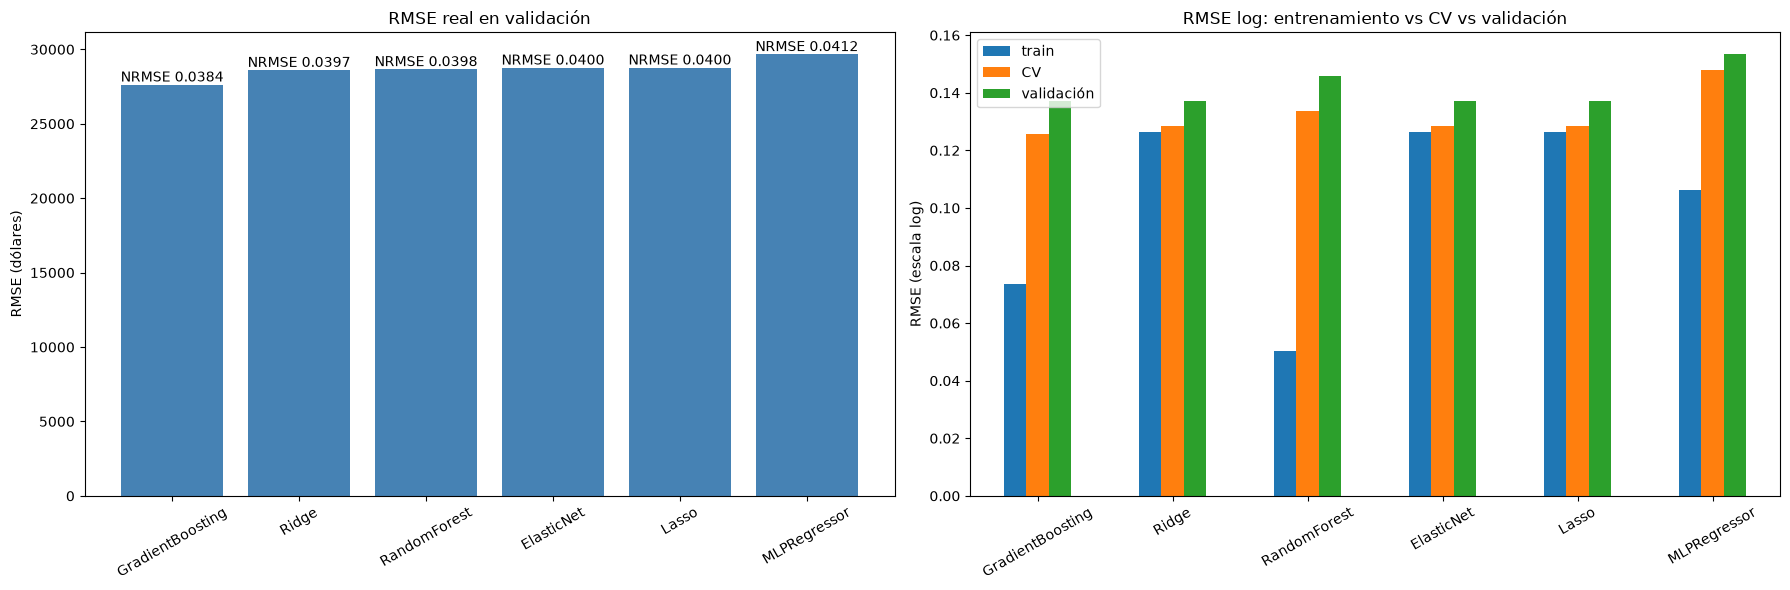

In [10]:
fig, (ax_rmse, ax_brecha) = plt.subplots(1, 2, figsize=(18, 6))

barras = ax_rmse.bar(torneo["modelo"], torneo["rmse_real_val"], color="steelblue")
ax_rmse.bar_label(barras, labels=[f"NRMSE {valor:.4f}" for valor in torneo["nrmse_rango_val"]])
ax_rmse.set_title("RMSE real en validación")
ax_rmse.set_ylabel("RMSE (dólares)")
ax_rmse.tick_params(axis="x", rotation=30)

(
    torneo.set_index("modelo")[["rmse_log_train", "rmse_log_cv", "rmse_log_val"]]
    .rename(columns={"rmse_log_train": "train", "rmse_log_cv": "CV", "rmse_log_val": "validación"})
    .plot.bar(ax=ax_brecha)
)
ax_brecha.set_title("RMSE log: entrenamiento vs CV vs validación")
ax_brecha.set_ylabel("RMSE (escala log)")
ax_brecha.set_xlabel("")
ax_brecha.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Modelo ganador

El ganador es el modelo con el menor RMSE real en el set de validación.

In [11]:
ganador = torneo.iloc[0]
nombre_ganador = ganador["modelo"]
modelo_ganador = busquedas[nombre_ganador].best_estimator_
params_ganador = {
    param.replace("modelo__", ""): valor
    for param, valor in busquedas[nombre_ganador].best_params_.items()
}

print(f"Ganador: {nombre_ganador}")
print(f"Hiperparámetros: {params_ganador}")
print(f"RMSE real validación: {ganador['rmse_real_val']:,.0f}")
print(f"NRMSE (rango) validación: {ganador['nrmse_rango_val']:.4f}")
print(f"RMSE log CV: {ganador['rmse_log_cv']:.4f}")

Ganador: GradientBoosting
Hiperparámetros: {'learning_rate': 0.03, 'max_depth': 3}
RMSE real validación: 27,615
NRMSE (rango) validación: 0.0384
RMSE log CV: 0.1256


## Guardar el modelo ganador

El ganador se reentrena con el 100% de `train.csv` (entrenamiento + validación), con los mismos hiperparámetros elegidos en el torneo, para aprovechar todos los datos con target. Se clona el pipeline completo (feature engineering + modelo) para que tanto el feature engineering como el modelo se vuelvan a ajustar con todos los datos. Las métricas reportadas siguen siendo las del set de validación, medidas antes de este reentrenamiento.

El pipeline se guarda en `models/` con joblib: recibe los datos crudos con las `MODEL_FEATURES` y predice en escala log (se regresa a dólares con `np.expm1`). El resultado del torneo se agrega a `pipeline_config.yaml`.

In [12]:
# Reentrenamiento del pipeline completo (feature engineering + modelo) con el 100% de train.csv
modelo_final = clone(modelo_ganador).fit(X, y)

MODELS_DIR.mkdir(parents=True, exist_ok=True)
ruta_modelo = MODELS_DIR / MODELO_FILE
joblib.dump(modelo_final, ruta_modelo)


def a_tipo_yaml(valor):
    """Convierte tuplas y tipos de numpy a tipos que yaml.safe_dump puede guardar."""
    if isinstance(valor, tuple):
        return list(valor)
    if isinstance(valor, np.generic):
        return valor.item()
    return valor


config["BEST_MODEL"] = {
    "nombre": nombre_ganador,
    "hiperparametros": {param: a_tipo_yaml(valor) for param, valor in params_ganador.items()},
    "k_folds": K_FOLDS,
    "rmse_log_cv": float(ganador["rmse_log_cv"]),
    "rmse_real_val": float(ganador["rmse_real_val"]),
    "nrmse_rango_val": float(ganador["nrmse_rango_val"]),
    "entrenado_con": f"{TRAIN_FILE} completo ({len(X)} casas: entrenamiento + validación)",
    "ruta": Path(os.path.relpath(ruta_modelo, PROJ_DIR)).as_posix(),
}

with open(CONFIG_FILE, "w", encoding="utf-8") as archivo:
    yaml.safe_dump(config, archivo, sort_keys=False, allow_unicode=True)

print(f"Pasos del pipeline guardado: {[nombre for nombre, _ in modelo_final.steps]}")
print(f"Casas usadas en el reentrenamiento: {len(X)}")
print(f"Modelo guardado en: {ruta_modelo.resolve()}")
print(f"Configuración guardada en: {CONFIG_FILE.resolve()}")

Pasos del pipeline guardado: ['fe', 'modelo']
Casas usadas en el reentrenamiento: 1460
Modelo guardado en: C:\Users\Usuario\OneDrive\Desktop\2026\Maestria\Cuarto Trimestre\PRODUCT DEVELOPMENT\Clase 2\clase_2\models\modelo_ganador.joblib
Configuración guardada en: C:\Users\Usuario\OneDrive\Desktop\2026\Maestria\Cuarto Trimestre\PRODUCT DEVELOPMENT\Clase 2\clase_2\pipeline_config.yaml


## Exportar los resultados del torneo

Se guardan en `reports/` los resultados del torneo, para evaluarlos en el notebook de evaluación de modelos sin repetir la búsqueda:

- `torneo_cv.csv`: todas las configuraciones probadas de cada modelo con sus errores de validación cruzada.
- `torneo_validacion.csv`: métricas de la mejor configuración de cada modelo en el set de validación.
- `torneo_mejores_modelos.yaml`: clase y parámetros completos de la mejor configuración de cada modelo, para reconstruirlos.

In [ ]:
REPORTS_DIR = Path(os.getenv("REPORTS_DIR", PROJ_DIR / "reports"))
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

ruta_cv = REPORTS_DIR / "torneo_cv.csv"
ruta_validacion = REPORTS_DIR / "torneo_validacion.csv"
ruta_mejores = REPORTS_DIR / "torneo_mejores_modelos.yaml"

resultados_cv.assign(configuracion=resultados_cv["configuracion"].astype(str)).to_csv(
    ruta_cv, index=False
)
torneo.to_csv(ruta_validacion, index=False)

mejores_modelos = {
    nombre: {
        "clase": type(busqueda.best_estimator_.named_steps["modelo"]).__name__,
        "parametros": {
            param: a_tipo_yaml(valor)
            for param, valor in busqueda.best_estimator_.named_steps["modelo"].get_params().items()
        },
    }
    for nombre, busqueda in busquedas.items()
}
with open(ruta_mejores, "w", encoding="utf-8") as archivo:
    yaml.safe_dump(mejores_modelos, archivo, sort_keys=False, allow_unicode=True)

config["TOURNAMENT"] = {
    "cv": Path(os.path.relpath(ruta_cv, PROJ_DIR)).as_posix(),
    "validacion": Path(os.path.relpath(ruta_validacion, PROJ_DIR)).as_posix(),
    "mejores_modelos": Path(os.path.relpath(ruta_mejores, PROJ_DIR)).as_posix(),
}
with open(CONFIG_FILE, "w", encoding="utf-8") as archivo:
    yaml.safe_dump(config, archivo, sort_keys=False, allow_unicode=True)

for ruta in (ruta_cv, ruta_validacion, ruta_mejores):
    print(f"Guardado: {ruta.resolve()}")

## Registro en MLflow

El tracking y el Model Registry se guardan en una base SQLite local (`mlflow.db`), con los artefactos en `mlruns/`, ambos en la raíz del proyecto. Todo se registra en el experimento `house-pricing`.

Para ver los resultados, desde la raíz del proyecto:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

In [ ]:
# Configuración de MLflow: modificar estas variables si cambia el servidor o los nombres
MLFLOW_DB = Path(os.getenv("MLFLOW_DB", PROJ_DIR / "mlflow.db"))
MLFLOW_ARTIFACTS_DIR = Path(os.getenv("MLFLOW_ARTIFACTS_DIR", PROJ_DIR / "mlruns"))
MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", f"sqlite:///{MLFLOW_DB.resolve().as_posix()}")
EXPERIMENTO = "house-pricing"
MODELO_REGISTRADO = "house-pricing-saleprice"
ALIASES = ["champion", "challenger-1", "challenger-2"]  # en orden del ranking del torneo

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
if mlflow.get_experiment_by_name(EXPERIMENTO) is None:
    mlflow.create_experiment(EXPERIMENTO, artifact_location=MLFLOW_ARTIFACTS_DIR.resolve().as_uri())
mlflow.set_experiment(EXPERIMENTO)
cliente = MlflowClient()

config["MLFLOW"] = {
    "tracking_uri": "sqlite:///mlflow.db",
    "artifacts": "mlruns",
    "experimento": EXPERIMENTO,
    "modelo_registrado": MODELO_REGISTRADO,
    "aliases": ALIASES,
}
with open(CONFIG_FILE, "w", encoding="utf-8") as archivo:
    yaml.safe_dump(config, archivo, sort_keys=False, allow_unicode=True)

print(f"Tracking URI: {MLFLOW_TRACKING_URI}")
print(f"Experimento: {EXPERIMENTO}")

### Runs del torneo y Model Registry

Se crea un run por cada modelo del torneo con:

- **Parámetros:** la mejor configuración encontrada por la búsqueda, la clase del modelo y los parámetros de la validación cruzada.
- **Métricas:** RMSE en escala log de entrenamiento, CV y validación, RMSE real y NRMSE en validación, y la brecha de sobreajuste.
- **Artefactos:** todas las configuraciones probadas (`cv_configuraciones.csv`), los parámetros completos del modelo y las gráficas de desempeño en validación.

Los 3 mejores modelos del torneo se reentrenan con el 100% de `train.csv`, se envuelven para predecir `SalePrice` en dólares (igual que el pipeline de inferencia) y se registran como versiones de `house-pricing-saleprice` con los aliases `champion`, `challenger-1` y `challenger-2`.

In [ ]:
def modelo_en_dolares(pipeline_ajustado):
    """Envuelve un pipeline ajustado (escala log) para que prediga SalePrice en dólares, sin reentrenarlo."""
    return TransformedTargetRegressor(
        regressor=FrozenEstimator(pipeline_ajustado),
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=False,
    ).fit(X, np.expm1(y))


registro = []
for posicion, fila in torneo.iterrows():
    nombre = fila["modelo"]
    busqueda = busquedas[nombre]
    modelo = busqueda.best_estimator_.named_steps["modelo"]
    alias = ALIASES[posicion] if posicion < len(ALIASES) else None

    with mlflow.start_run(run_name=nombre) as run:
        mlflow.set_tags(
            {
                "etapa": "entrenamiento",
                "modelo": nombre,
                "posicion_torneo": posicion + 1,
                "rol": alias or "sin registro",
            }
        )
        mlflow.log_params(
            {
                "clase": type(modelo).__name__,
                "k_folds": K_FOLDS,
                "configuraciones_probadas": len(busqueda.cv_results_["params"]),
                "test_size": TEST_SIZE,
                "random_state": RANDOM_STATE,
                "n_features": len(MODEL_FEATURES),
                **{
                    param.replace("modelo__", ""): valor
                    for param, valor in busqueda.best_params_.items()
                },
            }
        )
        mlflow.log_metrics(
            {
                **{columna: float(fila[columna]) for columna in torneo.columns if columna != "modelo"},
                "rmse_log_cv_std": float(busqueda.cv_results_["std_test_score"][busqueda.best_index_]),
            }
        )
        mlflow.log_text(
            resultados_cv[resultados_cv["modelo"] == nombre].sort_values("ranking").to_csv(index=False),
            "cv_configuraciones.csv",
        )
        mlflow.log_dict(
            {param: str(valor) for param, valor in modelo.get_params().items()},
            "parametros_modelo.json",
        )
        fig_modelo, axes_modelo = plt.subplots(1, 3, figsize=(18, 5))
        graficar_desempeno(axes_modelo, nombre)
        fig_modelo.tight_layout()
        mlflow.log_figure(fig_modelo, "desempeno_validacion.png")
        plt.close(fig_modelo)

        version = None
        if alias:
            # El ganador ya se reentrenó con el 100% de train.csv al guardarlo
            pipeline_100 = (
                modelo_final if nombre == nombre_ganador else clone(busqueda.best_estimator_).fit(X, y)
            )
            modelo_registro = modelo_en_dolares(pipeline_100)
            info_modelo = mlflow.sklearn.log_model(
                sk_model=modelo_registro,
                name="modelo",
                signature=infer_signature(X, modelo_registro.predict(X)),
                input_example=X.head(5),
                pip_requirements=str(PROJ_DIR / "requirements.txt"),
                serialization_format="cloudpickle",
                registered_model_name=MODELO_REGISTRADO,
            )
            version = info_modelo.registered_model_version
            cliente.set_registered_model_alias(MODELO_REGISTRADO, alias, version)
            for clave, valor in {
                "modelo": nombre,
                "rmse_real_val": f"{fila['rmse_real_val']:.0f}",
                "nrmse_rango_val": f"{fila['nrmse_rango_val']:.4f}",
                "entrenado_con": f"{TRAIN_FILE} completo ({len(X)} casas)",
                "salida": "SalePrice en dólares",
            }.items():
                cliente.set_model_version_tag(MODELO_REGISTRADO, version, clave, valor)

    registro.append(
        {
            "posicion": posicion + 1,
            "modelo": nombre,
            "alias": alias or "—",
            "version": str(version) if version else "—",
            "run_id": run.info.run_id,
        }
    )

pd.DataFrame(registro)